# 06 — EfficientAD

Pilot-stage research notebook. Full benchmark is gated and has not started.

**Completed final benchmark:** all 45 frozen evaluations follow the preserved pilot/development history below. Historical pending statements remain as chronology. Final numeric outputs and aggregate plots are replayed from verified artifacts; licensed image panels are retained in the local full executed notebook. Notebook 07 is not started.

**Continuation:** the original pilot record is preserved below. The executed bounded-development study follows section 20 and supersedes historical pending-development statements. Final benchmark and Notebook 07 have not started.

## 1. Motivation

EfficientAD combines efficient local descriptors with global feature reconstruction. This notebook currently documents the reference review, implementation and real GPU pilot. Development and the frozen benchmark remain pending.

## 2. Paper review

Read Batzner et al., WACV 2024, using https://arxiv.org/html/2303.14535v3 after CVF returned 403. Algorithms 1–2 and Tables 6–8 define this implementation. See docs/efficientad_protocol.md for the source links and detailed derivation.

## 3. Teacher provenance

The teacher is the public third-party PDN-S checkpoint from nelson1425/EfficientAD, revision fcab5146f84ae17597044ad5ddf1656ccf805401. Repository Apache-2.0; no separate weight model card. Its accompanying code describes ImageNet WideResNet101_2 distillation; that history cannot be independently attested from tensors.

## 4. Architecture

PDN convolutions use channels 3→128→256→256→384, kernels 4,4,3,4 and average pooling after the first two. Paper padding gives 64×64 output and a 33-pixel local receptive field. The student outputs 768 channels. The global autoencoder has a 64×1×1 bottleneck. Medium capacity adds wider layers and 1×1 convolutions; it has not been measured here.

## 5. Loss mathematics

Normalize teacher channels with fitting-only population moments. D=(t−s1)²; Lhard=mean(D≥its .999 quantile). Lpenalty=mean(s1(P)²), Lae=mean((t−a)²), Lstae=mean((a−s2)²). Sum all four; no external P is available, so this pilot omits penalty. Lstae updates both branches.

## 6. Map mathematics

Local=mean_channels((t−s1)²); global=mean_channels((a−s2)²). Bilinearly resize to 256×256, normalize each as .1(M−q90)/(q99.5−q90), then average equally. Image score=max(combined map). Larger scores indicate anomalies. Final development scaling and reserved-normal threshold calibration are pending.

## 7. Environment and replay

The following code is saved-artifact replay of a separately executed real-data GPU pilot. It does not launch training. Live execution command: `.\.venv\Scripts\python.exe scripts/pilot_efficientad.py`; its append-only start event prevents accidental repeated fitting.

In [1]:
from pathlib import Path
import json, sys
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve() == ROOT/'.venv/Scripts/python.exe'
pilot = json.loads((ROOT/'reports/efficientad/pilot.json').read_text())
print('Saved-artifact replay:', pilot['experiment_id'], pilot['completed_utc'])

Saved-artifact replay: 06-pilot-bottle-seed2026-v1 2026-11-14T01:52:53.506988+00:00


Replay confirms the real pilot identity; it does not reproduce training or independently remeasure CUDA.

## 8. Dataset partitions

The existing frozen 70/15/15 normal partitions are unchanged. Pilot: bottle, seed 2026, first eight sorted fitting normals; no official test files, labels, masks or calibration normals were opened. Selected fitting images were checked against their SHA256 manifest.

## 9. Teacher preparation

Downloaded only the 10.8 MB checkpoint and repository license, not ImageNet. All teacher parameters are frozen. Pilot teacher moments and map scaling use the eight fitting normals solely for engineering checks. These statistics cannot be used as final benchmark calibration.

## 10. Core implementation

The next cell exposes reusable model code, including each scientific loss, normalization and map operation. The notebook is intended to make the process inspectable rather than hide it behind a single training API.

In [2]:
import inspect
from anomaly_detection import efficientad
print(inspect.getsource(efficientad))

"""EfficientAD-S, paper Tables 6/8 (padded 64x64 features).

Independent implementation from Batzner et al., WACV 2024. Checkpoint-compatible
PDN layer numbering with nelson1425/EfficientAD (Apache-2.0); no source copied.
Inputs are ImageNet-normalized RGB, 256x256. Teacher weights must be supplied.
"""
import torch
from torch import nn
from torch.nn import functional as F


def pdn(channels=384):
    return nn.Sequential(nn.Conv2d(3,128,4,padding=3),nn.ReLU(),
        nn.AvgPool2d(2,2,padding=1),nn.Conv2d(128,256,4,padding=3),
        nn.ReLU(),nn.AvgPool2d(2,2,padding=1),
        nn.Conv2d(256,256,3,padding=1),nn.ReLU(),nn.Conv2d(256,channels,4))


def autoencoder():
    layers=[]
    for a,b in zip((3,32,32,64,64),(32,32,64,64,64)):
        layers.extend((nn.Conv2d(a,b,4,2,1),nn.ReLU()))
    layers.append(nn.Conv2d(64,64,8))
    for size in (3,8,15,32,63,127):
        layers.extend((nn.Upsample(size=size,mode='bilinear',align_corners=False),
            nn.Conv2d(64,64,4,padding=2),

Each operation is visible above. The optional penalty accepts external images, but none were supplied in the recorded pilot.

## 11. Predeclared pilot

Before training, docs/milestone_status.md recorded 32 batch-one Adam steps at lr 1e−4, weight decay 1e−5, hard quantile .999. Fixed brightness 1.1 gives a repeatable AE learning probe; paper training uses randomized brightness/contrast/saturation. This is a disclosed engineering variant.

## 12. Actual pilot results

Replay the actual compact report below. The run verified finite losses and gradients, changes in student and AE parameters, decreased fixed-image hard and AE losses, finite 256×256 maps and exact checkpoint inference replay.

In [3]:
print(json.dumps({k:v for k,v in pilot.items() if k!='history'}, indent=2))

{
  "experiment_id": "06-pilot-bottle-seed2026-v1",
  "status": "passed",
  "before": {
    "hard": 17.107418060302734,
    "penalty": 0.0,
    "autoencoder": 0.9893844127655029,
    "student_autoencoder": 0.005611773114651442,
    "total": 18.102413177490234
  },
  "after": {
    "hard": 9.376309394836426,
    "penalty": 0.0,
    "autoencoder": 0.956558883190155,
    "student_autoencoder": 0.004149129614233971,
    "total": 10.337018013000488
  },
  "training_seconds": 5.0170549000031315,
  "seconds_per_step": 0.15678296562509786,
  "model_latency_ms": {
    "p50": 33.47220001160167,
    "p95": 145.27197999705095,
    "warmup": 20,
    "iterations": 100
  },
  "peak_process_rss_bytes": 1594490880,
  "process_peak_working_set_bytes": 1596932096,
  "peak_gpu_allocated_bytes": 318654464,
  "peak_gpu_reserved_bytes": 387973120,
  "parameters": {
    "teacher": 2694144,
    "student": 4267392,
    "autoencoder": 1096320
  },
  "feature_shape": [
    1,
    384,
    64,
    64
  ],
  "map_s

Hard loss fell from 17.1074 to 9.3763; AE loss fell from .98938 to .95656. This establishes short-run branch learning only. Model p50/p95 were 33.47/145.27 ms; these are measured on this laptop with deterministic FP32 settings.

## 13. Learning curves

These 32 steps are a short engineering trace, not evidence of convergence or anomaly quality. The image cycles every eight steps and dropout operates during training; fixed-image eval-mode before/after losses provide the cleaner learning check.

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


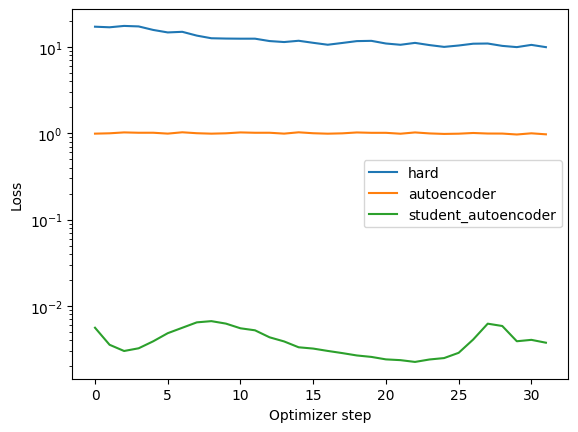

In [4]:
import matplotlib.pyplot as plt
for key in ('hard','autoencoder','student_autoencoder'):
    plt.plot([r['step'] for r in pilot['history']], [r[key] for r in pilot['history']], label=key)
plt.yscale('log'); plt.xlabel('Optimizer step'); plt.ylabel('Loss'); plt.legend(); plt.show()

The trace retains all 32 steps, including fluctuations, rather than presenting only favorable endpoints. It cannot establish anomaly discrimination or convergence.

## 14. Compute feasibility

The pilot step time can project an approximate 70,000-step paper-budget fit. Multiply by 45 for the requested all-category three-seed benchmark, then add data loading, evaluation and thermal margin. This extrapolation is not a measured full training runtime. Deterministic batch-one latency has a substantial p95 tail and needs further characterization.

In [5]:
seconds = pilot['seconds_per_step']
print({'estimated_70000_step_hours_per_model':seconds*70000/3600, 'estimated_45_model_training_hours':seconds*70000*45/3600, 'latency_ms':pilot['model_latency_ms']})

{'estimated_70000_step_hours_per_model': 3.048557664932458, 'estimated_45_model_training_hours': 137.18509492196063, 'latency_ms': {'p50': 33.47220001160167, 'p95': 145.27197999705095, 'warmup': 20, 'iterations': 100}}


At .1568 seconds per pilot step, linear projection is about 3.049 hours per 70k-step fit and 137.19 hours for 45 fits, excluding overhead. A full run is not yet validated; latency tails and sustained thermal behavior remain uncertain.

## 15. Bounded development plan

Proposed cap: 12 fits total, bottle and carpet, 2,000 steps each, seed 2026. Questions cover mean versus hard loss, AE contribution, map normalization, aggregation and capacity/budget. Penalty contrast requires legitimate documented external inputs and replaces another trial. No development fits have executed or been selected/rejected.

## 16. Model selection and calibration

Pending. No frozen final configuration or calibrated threshold exists. Later use development normals and fitting-derived synthetic proxies for selection, reserved calibration normals for strict score>threshold. Report sample size, nominal/observed FPR and uncertainty; no retrospective test tuning.

## 17. Frozen benchmark and metrics

Pending: zero final category-seed evaluations out of target 45. Image AUROC/AP, pixel AUROC/AP, AU-PRO, recall, FPR, precision and F1 are unavailable. No final metrics can be inferred from this normal-only pilot.

## 18. Failure analysis

Pending genuine test examples from all 15 categories after freeze. No false positive/negative claims are made. Later inspect scratches, textures, halos, logical/structural anomalies and localized responses missed by max aggregation alongside original images and masks; keep image panels local.

## 19. Six-model comparison

Pending EfficientAD evaluation. Previous Basic CNN, convolutional autoencoder, PatchCore, SuperSimpleNet Lite and PaDiM records remain unchanged. Later comparisons must match categories and report paired uncertainty, nine metrics, compute, memory and storage without unsupported superiority claims.

## 20. Validation, limitations and recovery

Focused core tests and deep pilot identity validation are provided. This notebook is a pilot-stage research record, not a completed milestone. No external penalty, only eight normals, fixed augmentation and 32 steps limit conclusions. Full development, calibration, benchmark, failure analysis and comparison remain. Notebook 07 is not started. Recovery instructions and current Git status are in docs/milestone_status.md.

### Development continuation — bounded study

The preceding 20 sections preserve the original pilot record and saved outputs. The following continuation supersedes its pending-development statements. It replays four newly executed fits and diagnostics; it does not launch training or final evaluation. The predeclared plan, fidelity audit and all successful or failed events are retained in the repository.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve() == ROOT/'.venv/Scripts/python.exe'
D = ROOT/'reports/efficientad/development'
plan = json.loads((ROOT/'configs/efficientad_development.json').read_text())
results = [json.loads(p.read_text()) for p in sorted(D.glob('06-dev-*-v1.json'))]
selection = json.loads((D/'selection.json').read_text())
gate = json.loads((D/'feasibility.json').read_text())
latency = json.loads((D/'latency.json').read_text())
print({'replay': True, 'fits': len(results), 'steps': sum(r['steps'] for r in results), 'plan': plan})

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


{'replay': True, 'fits': 4, 'steps': 4116, 'plan': {'study_id': '06-development-v1', 'model_name': 'EfficientAD-S reduced-budget variant', 'categories': ['bottle', 'carpet'], 'seed': 2026, 'epoch_budgets': [3, 9], 'fresh_fits': 4, 'maximum_optimizer_steps': 4116, 'development_wall_time_cap_hours': 2, 'batch_size': 1, 'image_size': 256, 'precision': 'deterministic FP32; TF32 disabled', 'optimizer': {'name': 'Adam', 'learning_rate': 0.0001, 'weight_decay': 1e-05}, 'lr_policy': 'constant within each reduced budget', 'hard_quantile': 0.999, 'external_penalty': False, 'augmentation': 'one uniformly random brightness/contrast/saturation, coefficient U(0.8,1.2), tensor RGB before ImageNet normalization', 'teacher_sha256': 'b98a6a139087a0d743783ee59f367f0284af6003eb1a5fed0ce92bd9c0acd337', 'map_policy': 'development-normal q90/q99.5, resized maps, no clipping', 'candidate_scores': ['combined_max', 'local_max'], 'diagnostic_scores_only': ['global_max', 'raw_combined_max', 'combined_top1pct'], '

The plan was saved before training: bottle (147 fit normals) and carpet (196), fresh seed-2026 models at 3 and 9 epochs, 4,116 optimizer steps total. This supersedes the earlier proposed 12-fit study. Fixed epochs expose every fitting normal equally. No official test images, masks or scores were opened; test counts/dimensions come only from prior metadata for cost estimates.

### Reference fidelity and implementation

Read the complete audit below. The architecture remains the padded PDN-S teacher/student and 64x1x1-bottleneck autoencoder. The reduced epoch budget, omitted external-image penalty, constant short-run learning rate and tensor photometric augmentation are disclosed differences from the paper. Missing external penalty may let the student imitate teacher features beyond normals; the effect on real anomalies has not been measured.

In [2]:
print((ROOT/'docs/efficientad_fidelity_audit.md').read_text(encoding='utf-8'))
import inspect
import importlib.util
spec = importlib.util.spec_from_file_location('efficientad_development_driver', ROOT/'scripts/develop_efficientad.py')
driver = importlib.util.module_from_spec(spec)
spec.loader.exec_module(driver)
print(inspect.getsource(driver.fit))

# EfficientAD fidelity audit for bounded development

Reference: Batzner et al., WACV 2024, author's arXiv v3 reviewed in the pilot
phase; Algorithms 1/2 and architecture Tables 6/8. This audit inspects existing
`src/anomaly_detection/efficientad.py`; the architecture is not replaced.

| Component | Current implementation | Assessment |
|---|---|---|
| Teacher PDN-S | Four Conv2d layers, 128/256/256/384, 4/4/3/4 kernels, average pools, paper padding | Matches padded Table 6; 384x64x64 on 256 RGB |
| Teacher training status | `requires_grad_(False)`, `train()` override calls teacher.eval(), feature extraction under no_grad | Frozen; focused tests assert no teacher gradients |
| Teacher normalization | Channel population moments across fitting images and spatial positions, float64 accumulation | Full fitting partition for development, unlike eight-image pilot; variance floor 1e-12 is a numerical safeguard |
| Student | Same padded PDN, 768 output channels; first/last 384 heads | Matches 

def fit(category,epochs,rows,images,dev_rows,dev_images,plan):
    identifier=f'06-dev-{category}-e{epochs}-seed2026-v1'
    result_path=OUT/f'{identifier}.json'; checkpoint=CKPT/f'{identifier}.pt'
    if result_path.exists():
        result=json.loads(result_path.read_text())
        assert sha256(checkpoint)==result['checkpoint']['sha256']
        assert result['plan_sha256']==sha256(PLAN)
        assert (ROOT/f'experiments/{identifier}-result.json').exists()
        print('Reuse verified fit',identifier,flush=True)
        return result
    assert not (ROOT/f'experiments/{identifier}-start.json').exists(), 'Incomplete fit: inspect saved events/checkpoints before recovery'
    params=dict(categories=[category],epochs=epochs,steps=epochs*len(images),seed=2026,plan_sha256=sha256(PLAN))
    event(identifier+'-start','Full-epoch budget controls learning, normal score stability and paired synthetic discrimination',params)
    try:
        begin=time.perf_counter(); torch.manual_seed(2026)

The training code explicitly exposes shuffle order, random augmentation, hard loss, joint AE objectives, finite-gradient checks and complete-epoch timing. Teacher moments use every fitting normal and are cached by teacher/manifest/core identity for the second budget. Every completed fit has a checkpoint, map quantiles, exact replay check, result JSON, CSV diagnostics and append-only registry result. No existing pilot architecture was reimplemented.

### Latency diagnosis

Use the same saved pilot checkpoint for a controlled measurement audit: identical 1x3x256x256 FP32 input and unchanged model semantics. After 50 warmups per repeat, synchronize around 100 resident-input forwards in each of three repeats and record both wall and CUDA event time. Transfer and file-decode-through-CPU-map paths are timed separately. Events include stream launch gaps, so they are not a sum of isolated kernel durations.

{
  "methodology": "Same deterministic FP32 model, no semantic changes. 50 warmups/repeat, resident 1x3x256x256 input. Explicit synchronization and CUDA events; event time includes stream launch gaps. End-to-end includes file decode, CPU preprocessing, H2D, forward, D2H map and score.",
  "resident_wall": {
    "p50_ms": 41.98589999577962,
    "p95_ms": 54.11163998651319,
    "count": 300
  },
  "resident_gpu_event": {
    "p50_ms": 41.916303634643555,
    "p95_ms": 53.26419506072999,
    "count": 300
  },
  "per_repeat": [
    {
      "repeat": 0,
      "wall": {
        "p50_ms": 42.76404999836814,
        "p95_ms": 53.3351949925418,
        "count": 100
      },
      "gpu": {
        "p50_ms": 42.689537048339844,
        "p95_ms": 53.01920394897461,
        "count": 100
      }
    },
    {
      "repeat": 1,
      "wall": {
        "p50_ms": 41.30944999633357,
        "p95_ms": 56.56145499669947,
        "count": 100
      },
      "gpu": {
        "p50_ms": 41.23852729797363,
   

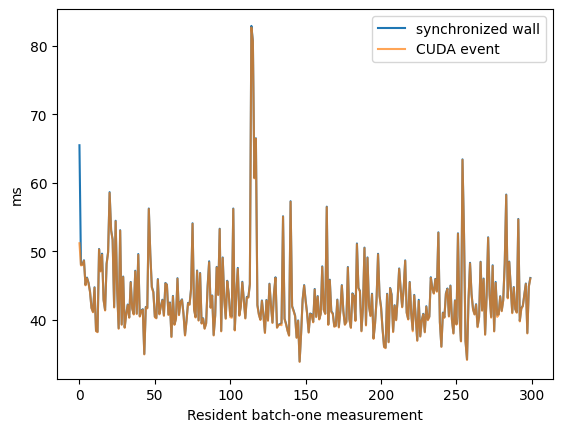

In [3]:
print(json.dumps({k:v for k,v in latency.items() if k not in ('samples','end_to_end_samples_ms','transfer_samples_ms')}, indent=2))
wall = np.array([r['wall_ms'] for r in latency['samples']])
events = np.array([r['gpu_ms'] for r in latency['samples']])
plt.plot(wall, label='synchronized wall'); plt.plot(events, label='CUDA event', alpha=.7)
plt.xlabel('Resident batch-one measurement'); plt.ylabel('ms'); plt.legend(); plt.show()

Resident wall p50/p95 = 41.99/54.11 ms, CUDA event = 41.92/53.26 ms (300 runs). End-to-end = 47.14/80.44 ms (100 runs); H2D = 0.274/0.402 ms. This run has a smaller p95 than the pilot, without a faster median. P0 and sampled clocks were stable; bursts did not remove the cost. CPU process usage near one core and modest GPU utilization are consistent with host/driver launch overhead. Windows scheduling remains a possible cause, not proven. No power/clock settings or score semantics were changed.

### Exploratory host-launch control, after selection

The initial audit motivates an execution-only CUDA graph control on the selected bottle checkpoint. It is run after the four fits and selection, and cannot influence model selection. Eager and graph execute the same full model, including both maps. Equality is checked before timing and on three additional normal inputs; capture failure is retained. Graph timing excludes capture and transfers and is not silently substituted into the final compute estimate.

In [4]:
control = json.loads((D/'launch-control.json').read_text())
print(json.dumps({k:v for k,v in control.items() if k not in ('eager','graph')},indent=2))
print({k:{m:v[m] for m in ('wall','gpu_event')} for k,v in control.items() if k in ('eager','graph')})

{
  "purpose": "Exploratory execution-only control after selection, no architecture/weight/score change. Graph replay is not silently adopted for final timing or feasibility.",
  "selected_checkpoint": {
    "experiment_id": "06-dev-bottle-e9-seed2026-v1",
    "plan_sha256": "f6953af23b5bee0564c9ca1010191885ffa549013bbcfbd429d163383e994d8e",
    "teacher_sha256": "b98a6a139087a0d743783ee59f367f0284af6003eb1a5fed0ce92bd9c0acd337",
    "epochs": 9,
    "category": "bottle",
    "seed": 2026,
    "final": false
  },
  "shape": [
    1,
    3,
    256,
    256
  ],
  "precision": "deterministic FP32",
  "warmup": 50,
  "repeats": 3,
  "iterations_per_repeat": 100,
  "graph_max_abs_error": [
    0.0,
    0.0
  ],
  "graph_bitwise_equal": true,
  "additional_input_max_abs_errors": [
    0.0,
    0.0,
    0.0,
    0.0,
    0.0,
    0.0
  ],
  "graph_status": "measured",
  "profiler_table": "-------------------------------------------------------  ------------  ------------  ------------  ----

The paired eager wall p50/p95 is 25.98/32.23 ms; fixed-shape graph replay is 19.26/19.63 ms (300 each). Graph capture, image transfer and preprocessing are excluded. A lower graph time supports host-dispatch overhead as a contributor, without identifying a specific Windows scheduling mechanism. All subsequent feasibility arithmetic conservatively retains eager timing. This exploratory control changes execution scheduling, not architecture, weights or anomaly-score definitions.

### Full-epoch learning curves

Every plotted point below is a recorded full epoch. Training means include hard-feature, autoencoder and student-autoencoder loss; held-out normal maxima track unnormalized score drift without repeatedly refitting maps. A falling loss is necessary but does not establish anomaly sensitivity. Fixed fitting probes before/after also separate training-mode dropout fluctuations from actual learning.

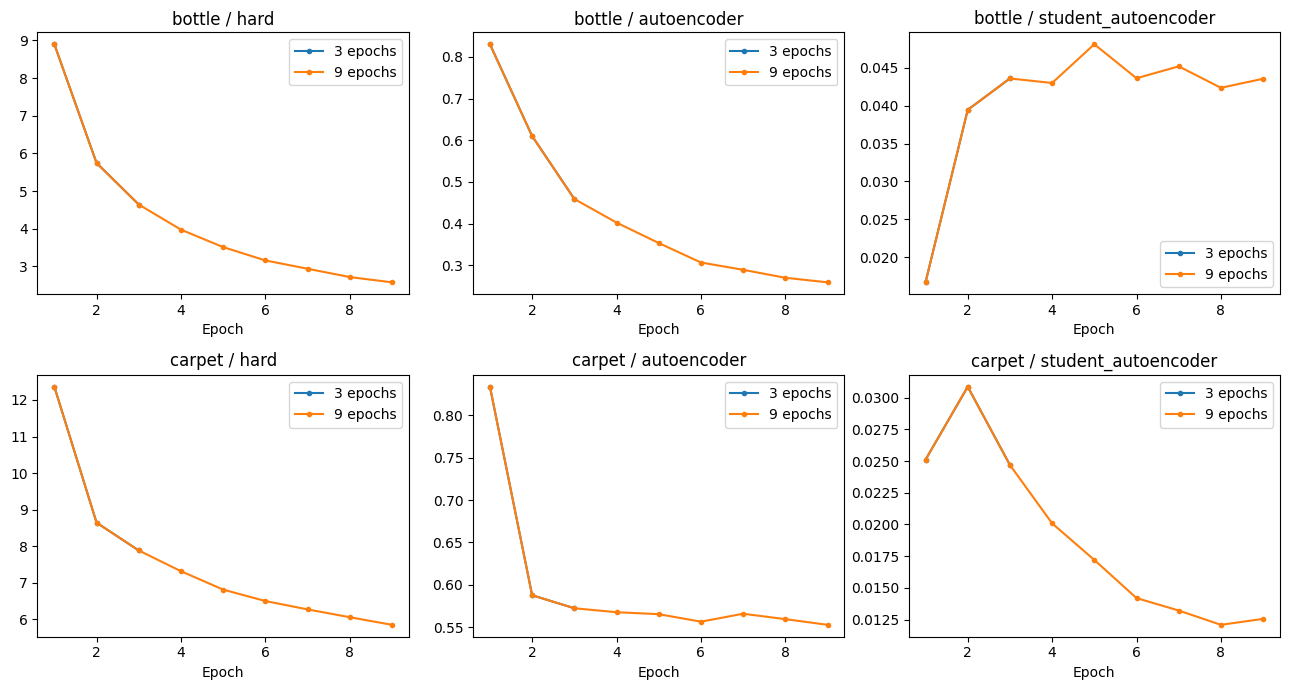

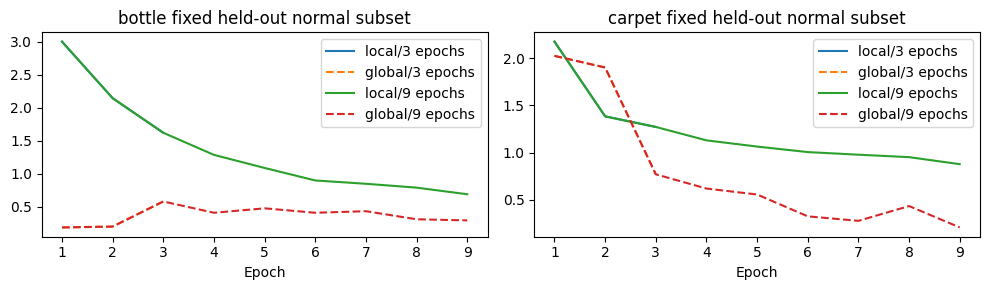

category  epochs  steps  train_seconds  hard_before  hard_after  ae_before  ae_after                                                                                                                                         development_probe
  bottle       3    441      65.620688    17.999707    4.273714   1.003767  0.426524   {'hard': 4.18828159570694, 'penalty': 0.0, 'autoencoder': 0.41827185451984406, 'student_autoencoder': 0.02890788810327649, 'total': 4.6354615688323975}
  bottle       9   1323     185.597321    17.999707    2.399083   1.003767  0.230009 {'hard': 2.379307448863983, 'penalty': 0.0, 'autoencoder': 0.22196530550718307, 'student_autoencoder': 0.021848079282790422, 'total': 2.6231207847595215}
  carpet       3    588      65.866850    21.076909    8.210890   1.088874  0.612716  {'hard': 9.347878456115723, 'penalty': 0.0, 'autoencoder': 0.6544092148542404, 'student_autoencoder': 0.015717095928266644, 'total': 10.018004894256592}
  carpet       9   1764     226.663999    21

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(13,7))
for i, category in enumerate(plan['categories']):
    for r in results:
        if r['category'] != category: continue
        curves = pd.DataFrame(r['curves'])
        for j,key in enumerate(('hard','autoencoder','student_autoencoder')):
            axes[i,j].plot(curves.epoch, curves[key], marker='.', label=f"{r['epochs']} epochs")
            axes[i,j].set_title(category+' / '+key); axes[i,j].set_xlabel('Epoch'); axes[i,j].legend()
fig.tight_layout(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax,category in zip(axes,plan['categories']):
    for r in results:
        if r['category'] != category: continue
        curves = pd.DataFrame(r['curves'])
        ax.plot(curves.epoch,curves.raw_local_dev_max_median,label=f"local/{r['epochs']} epochs")
        ax.plot(curves.epoch,curves.raw_global_dev_max_median,linestyle='--',label=f"global/{r['epochs']} epochs")
    ax.set_title(category+' fixed held-out normal subset'); ax.set_xlabel('Epoch'); ax.legend()
fig.tight_layout(); plt.show()
print(pd.DataFrame([dict(category=r['category'],epochs=r['epochs'],steps=r['steps'],train_seconds=r['training_seconds'],hard_before=r['probe_before']['hard'],hard_after=r['probe_after']['hard'],ae_before=r['probe_before']['autoencoder'],ae_after=r['probe_after']['autoencoder'],development_probe=r['development_probe_losses']) for r in results]).to_string(index=False))

All meaningful epoch fluctuations are retained. Compare the fixed-probe endpoints and held-out development score drift with the synthetic discrimination table below. Different score scales across budgets are expected before development-map normalization; they do not by themselves imply worsening normal false alarms. This study has one development seed and cannot establish across-seed stability.

### Proxy discrimination and autoencoder contribution

For 16 fitting normals per category, deterministic scratch, block and color edits yield 48 synthetic anomalous images. Their backgrounds participated in fitting, so results are optimistic proxies rather than real-defect generalization. Report each edit and paired score change. Combined versus local-only is an inference map ablation with identical trained weights; global-only, raw-map and top-1%-mean are diagnostic scores, not extra selected trials.

In [6]:
rows = []
for r in results:
    for score,v in r['proxy'].items():
        rows.append(dict(category=r['category'],epochs=r['epochs'],score=score,proxy_auroc=v['auroc'],proxy_ap=v['ap'],scratch=v['per_edit']['scratch'],block=v['per_edit']['block'],color_patch=v['per_edit']['color_patch'],paired_delta=v['mean_paired_score_delta']))
print(pd.DataFrame(rows).to_string(index=False))
print('Development-normal score distributions and leave-one-image-out map-scaling ranges:')
for r in results:
    print(r['experiment_id'], r['development_score_distributions'], r['leave_one_development_image_out_quantile_range'])
print('Across-budget normal score rank correlations:')
from scipy.stats import spearmanr
for category in plan['categories']:
    tables = [pd.read_csv(D/f"06-dev-{category}-e{e}-seed2026-v1-development.csv").set_index('path') for e in plan['epoch_budgets']]
    print(category, {s: float(spearmanr(tables[0][s],tables[1].loc[tables[0].index,s]).statistic) for s in plan['candidate_scores']})

category  epochs            score  proxy_auroc  proxy_ap  scratch    block  color_patch                                                                                            paired_delta
  bottle       3     combined_max     0.674479  0.895321 0.687500 0.335938     1.000000    {'scratch': 0.07549706101417542, 'block': -0.0016382485628128052, 'color_patch': 31.136669158935547}
  bottle       3        local_max     0.878255  0.942708 0.833984 0.800781     1.000000        {'scratch': 0.2643268406391144, 'block': 0.07223925739526749, 'color_patch': 20.223596572875977}
  bottle       3       global_max     0.592448  0.853732 0.441406 0.335938     1.000000  {'scratch': -0.0008839331567287445, 'block': -0.0032765045762062073, 'color_patch': 42.11472702026367}
  bottle       3 raw_combined_max     0.701823  0.906778 0.722656 0.382812     1.000000      {'scratch': 0.24004849791526794, 'block': 0.0009313970804214478, 'color_patch': 39.74135971069336}
  bottle       3 combined_top1pct     0.

C:\Users\shaik\AppData\Local\Temp\ipykernel_23484\3716876864.py:13: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  print(category, {s: float(spearmanr(tables[0][s],tables[1].loc[tables[0].index,s]).statistic) for s in plan['candidate_scores']})


The sensitivity varies by edit and category; none of these scores is official-test AUROC. Proxy AP has a .75 random-ranking reference because 48 of 64 proxy-panel images are edited, and edits share only 16 backgrounds. Normal development distributions and leave-one-out map quantiles expose scaling instability without using reserved calibration for selection. Rejected score diagnostics remain in every CSV. Structural/logical anomalies and fine real scratches remain untested. See the selection table for the predeclared decision rather than choosing the best individual edit retrospectively.

### Configuration selection, locked before calibration

Eligibility requires finite losses/gradients/maps, lower fitting-probe hard and AE losses, and proxy AUROC at least .65 in each category. Rank macro proxy AUROC; select three epochs if within .02 of the best eligible nine-epoch candidate, and prefer combined-max within .02 of local-max. The selection JSON was written before opening reserved calibration images.

In [7]:
print(json.dumps(selection, indent=2))
print('Candidate decisions:')
print(pd.DataFrame(selection['candidates']).to_string(index=False))

{
  "eligible": true,
  "candidates": [
    {
      "epochs": 3,
      "score": "combined_max",
      "eligible": true,
      "macro_proxy_auroc": 0.7936197916666666,
      "worst_category_proxy_auroc": 0.6744791666666666
    },
    {
      "epochs": 3,
      "score": "local_max",
      "eligible": true,
      "macro_proxy_auroc": 0.9287109375000001,
      "worst_category_proxy_auroc": 0.8782552083333335
    },
    {
      "epochs": 9,
      "score": "combined_max",
      "eligible": true,
      "macro_proxy_auroc": 0.97265625,
      "worst_category_proxy_auroc": 0.9466145833333333
    },
    {
      "epochs": 9,
      "score": "local_max",
      "eligible": true,
      "macro_proxy_auroc": 0.9947916666666666,
      "worst_category_proxy_auroc": 0.9908854166666666
    }
  ],
  "selected": {
    "epochs": 9,
    "score": "local_max",
    "eligible": true,
    "macro_proxy_auroc": 0.9947916666666666,
    "worst_category_proxy_auroc": 0.9908854166666666
  },
  "plan_sha256": "f6953af23b5b

Selected **9 epochs, local_max**, eligibility=True, macro proxy AUROC=0.9948. This is the predeclared decision, not a paper-equivalence claim. The exact .65/.02 criteria and both rejected budgets/scores remain visible. Calibration results below do not alter this selection. The reduced configuration is named EfficientAD-S reduced-budget variant.

### Reserved-normal calibration feasibility

After the selection lock, use all reserved clean calibration normals: 31 bottle and 42 carpet. Freeze nominal 5% FPR, higher 95th percentile, strict score>threshold. Bootstrap 1,000 times and delete one sample at a time to expose threshold sensitivity. Also report the continuous-IID order-statistic future-FPR interval. A binomial interval on reused calibration exceedances is descriptive, not coverage for a fitted threshold.

[
  {
    "threshold": 0.5066908597946167,
    "nominal_fpr": 0.05,
    "strict_greater": true,
    "quantile_method": "higher",
    "calibration_distribution": {
      "n": 31,
      "min": 0.5066908597946167,
      "median": 0.5066908597946167,
      "mean": 0.5066908597946167,
      "std": 0.0,
      "q90": 0.5066908597946167,
      "q95": 0.5066908597946167,
      "max": 0.5066908597946167
    },
    "observed_calibration_fpr": 0.0,
    "exceedances": 0,
    "calibration_exceedance_descriptive_cp95": [
      0.0,
      0.11218874692236996
    ],
    "uncertainty_note": "Tied calibration scores violate the continuous-score assumption: Beta future-FPR interval is not asserted. The retained hypothetical interval is reference only; degenerate bootstrap tails do not establish certainty. CP calibration interval is descriptive because threshold was fitted on those samples.",
    "bootstrap_threshold_p025_p50_p975": [
      0.5066908597946167,
      0.5066908597946167,
      0.506690859794

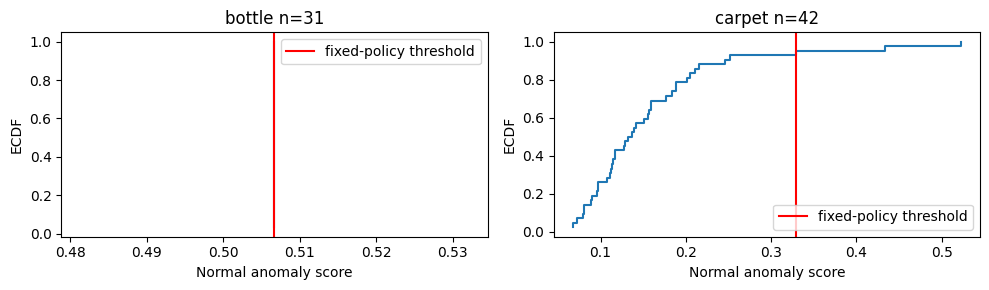

In [8]:
calibration = [json.loads((D/f'calibration-{c}-corrected.json').read_text()) for c in plan['categories']]
print(json.dumps(calibration,indent=2))
print('Precision audit:',json.loads((D/'calibration-precision-audit.json').read_text()))
fig, axes = plt.subplots(1,2,figsize=(10,3))
for ax,c in zip(axes,calibration):
    table=pd.read_csv(D/f"{c['category']}-calibration-exact-scores.csv",float_precision='round_trip')
    values=np.sort(table.score)
    ax.step(values,np.arange(1,len(values)+1)/len(values),where='post')
    ax.axvline(c['threshold'],color='red',label='fixed-policy threshold')
    ax.set_title(c['category']+f" n={len(values)}"); ax.set_xlabel('Normal anomaly score'); ax.set_ylabel('ECDF'); ax.legend()
fig.tight_layout(); plt.show()

The precision audit repairs an evaluation serialization error: rounded float32 decimal values read as float64 inflated bottle development exceedances. Original reports are preserved; exact values are now promoted before export and parsed with round-trip precision. No training, score definition, threshold or model selection changed. Bottle has one unique calibration score across 31 normals; its identical maximum is a score floor, while spatial maps still vary. The zero-width bootstrap range is not certainty; the continuous-score Beta interval is inapplicable and explicitly null. Carpet retains a wide bootstrap range. The smaller all-category calibration partitions (for example toothbrush n=9) will be still less precise. No calibration observations select a different setting or justify a post-test adjustment.

### Measured compute and 45-model feasibility

Use complete-epoch timings from both categories, retaining the slower selected-budget seconds/image. Add measured full-fitting normalization/preparation, normal map scaling, calibration, decode-through-CPU-map inference, checkpoint serialization/reload, synthetic native-metric N log N cost, and 60 seconds/model fixed CPU artifact/validation overhead. Multiply the entire sequential elapsed estimate by two. Test counts and dimensions are metadata-only; no test pixels or masks were accessed.

In [9]:
print(pd.DataFrame([dict(category=r['category'],epochs=r['epochs'],train_s=r['training_seconds'],seconds_per_image_epoch=r['seconds_per_image_epoch'],prep_s=r['preparation_seconds'],diagnostics_s=r['diagnostic_seconds'],serialization_validation_s=r['serialization_validation_seconds'],ram_bytes=r['process_peak_working_set_bytes'],gpu_allocated_bytes=r['peak_gpu_allocated_bytes'],gpu_reserved_bytes=r['peak_gpu_reserved_bytes']) for r in results]).to_string(index=False))
print(json.dumps({k:v for k,v in gate.items() if k!='workload'},indent=2))
print(pd.DataFrame([dict(category=r['category'],**r['per_model_seconds'],three_seed_conservative_hours=r['conservative_three_seed_seconds']/3600) for r in gate['workload']]).to_string(index=False))

category  epochs    train_s  seconds_per_image_epoch   prep_s  diagnostics_s  serialization_validation_s  ram_bytes  gpu_allocated_bytes  gpu_reserved_bytes
  bottle       3  65.620688                 0.148800 1.441082      62.731987                    0.638044 1973071872            329485312           455081984
  bottle       9 185.597321                 0.140285 0.149494      33.753909                    0.621206 1974784000            329565184           455081984
  carpet       3  65.866850                 0.112018 1.708653      63.792810                    0.551636 2111066112            329565184           455081984
  carpet       9 226.663999                 0.128494 0.098296      67.662803                    0.566080 2111066112            329565184           455081984
{
  "recommendation": "GO",
  "target_hours": 12,
  "estimated_conservative_total_elapsed_hours": 10.158889779561685,
  "estimated_training_hours_no_margin": 2.684006603460687,
  "models": 45,
  "categories": 15,
  

The conservative estimate is **10.16 hours for 45 models**, including CPU work and a factor-two margin; raw projected training is 2.68 hours. Recommendation: **GO** against the 12-hour target. This is a cost forecast, not measured final GPU-hours; sustained thermals, other categories and exact native metric workloads may differ. All 15 categories and seeds 2026/2027/2028 remain planned. No final model has been trained by this phase.

### Development conclusion and remaining milestone work

Four fits and their complete learning histories, latency audit, fidelity audit, calibration sensitivity and feasibility arithmetic are retained. Teacher provenance and separate checkpoint-license uncertainty remain unchanged. Missing penalty, short training, one development seed, optimistic proxies and small calibration tails limit the evidence. Final nine metrics, real category-specific failures and six-model comparison remain unavailable until a frozen benchmark. Notebook 07 remains unstarted. Validation and recovery evidence live in docs/milestone_status.md and reports/efficientad/development/validation.json.

### Frozen final benchmark — executed research continuation

The preceding pilot and bounded-development cells and outputs are preserved as historical evidence. This continuation documents 45 newly trained and evaluated category-seed models, after the reduced protocol was frozen. Every cell below is **saved-artifact replay**, not live training. The live command was project Python `scripts/run_efficientad_final.py --all`; recovery uses its manifest, epoch snapshots and verified completed artifacts. No official test outcome changed training, scoring or calibration.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd() if (Path.cwd()/'reports').exists() else Path.cwd().parent
assert Path(sys.executable).resolve()==ROOT/'.venv/Scripts/python.exe'
R=ROOT/'reports/efficientad'
summary=json.loads((R/'summary.json').read_text())
runs=pd.read_csv(R/'all_runs.csv',float_precision='round_trip')
manifest=json.loads((R/'final/benchmark_manifest.json').read_text())
frozen=json.loads((ROOT/'configs/efficientad_reduced_frozen.json').read_text())
metrics=['image_auroc','image_ap','pixel_auroc','pixel_ap','au_pro','recall','fpr','precision','f1']
print({'models':len(runs),'categories':runs.category.nunique(),'seeds':sorted(runs.seed.unique().tolist()),'frozen_configuration':frozen,'replay':True})

{'models': 45, 'categories': 15, 'seeds': [2026, 2027, 2028], 'frozen_configuration': {'schema': 1, 'name': 'EfficientAD-S reduced-budget variant', 'development_gate': 'GO', 'categories': ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper'], 'seeds': [2026, 2027, 2028], 'epochs': 9, 'score': 'local_max', 'batch_size': 1, 'size': 256, 'teacher': {'path': 'checkpoints/efficientad/assets/teacher_small.pth', 'source': 'nelson1425/EfficientAD', 'revision': 'fcab5146f84ae17597044ad5ddf1656ccf805401', 'sha256': 'b98a6a139087a0d743783ee59f367f0284af6003eb1a5fed0ce92bd9c0acd337', 'license': 'repository Apache-2.0; separate weight license unconfirmed'}, 'teacher_normalization': 'all fitting normals only; channel population moments', 'external_penalty': False, 'hard_quantile': 0.999, 'optimizer': {'name': 'Adam', 'learning_rate': 0.0001, 'weight_decay': 1e-05}, 'lr_policy': 'constant within each

Coverage is 15 categories by seeds 2026/2027/2028. Each model was freshly initialized and trained for nine full epochs. Frozen-file fields saying zero final models/evaluator not executed are immutable pre-benchmark metadata; the benchmark manifest and result records give current completion. Teacher normalization uses all fitting normals; teacher identity is unchanged. Both student heads and AE objectives remain trained, while the selected image/pixel map is the normalized local teacher/student discrepancy. No external penalty, test-guided border cropping, score clipping, sigmoid, smoothing or threshold tuning was introduced.

### Readiness, durability and the exact executed procedure

Readiness checked the exact project interpreter, CUDA/RTX 4060, 15 categories, source/teacher/partition/freeze hashes, free disk and competing processes. Per-epoch snapshots contain model, optimizer, NumPy and torch CPU/CUDA RNG state. A run becomes complete only after official evaluation, checkpoint replay, exact score serialization, metric reconciliation and artifact hashing. The following source is displayed for scientific inspection; importing it does not launch fitting.

In [2]:
import inspect
from anomaly_detection import efficientad_final as final
print((ROOT/'docs/efficientad_final_protocol.md').read_text(encoding='utf-8'))
print(inspect.getsource(final.train))
print(inspect.getsource(final.evaluate))
print('Resource gate:',json.loads((R/'final/resource_gate.json').read_text()))

# Frozen EfficientAD final execution protocol

Continuation of 664e106dbdd25104ea4e3c3be192fc8be7a0b772. No model-selection
change. Configuration SHA256 d728cf544ebc6f0c3d012adbca044a7aa5ddf4c0ced2e3210bef19b77a71d321.
All 15 categories, seeds 2026/2027/2028, fresh models, nine full shuffled epochs.
Training follows the existing development recipe exactly: full fitting-only
teacher moments, dual-head student and auxiliary AE, hard/AE/STAE losses,
tensor photometric augmentation, constant Adam, deterministic FP32, no penalty.
All development/provenance limitations remain. No pilot/development run is final.

The selected anomaly map and image score are the normalized local teacher/student
map and its maximum at 256 resolution. Full local/global raw maps are retained
for analysis; global/combined scores cannot replace the selected final score.
Map q90/q99.5 use only development normals. Scoring uses the existing CPU float32
map normalization helper, then promotes exact scores to float64 b

This makes the chronological scientific operations inspectable: fit teacher moments, train exact fixed epochs, scale maps on development normals, save/replay the checkpoint, fit reserved-normal thresholds, then open test images and masks. Completed attempts are immutable; valid results are checked before skipping. Manager resource decisions depend on measured cost and disk availability, not test quality. Previous milestones and the successful pilot/development runs were not rerun.

### All 45 histories and learning curves

The plotted points are the actual recorded epoch means. All three seeds are shown per category, including fluctuations. Low training losses do not establish anomaly sensitivity; test ranking and calibrated operating metrics are reported separately. The AE remains trained even though its map was rejected during development selection.

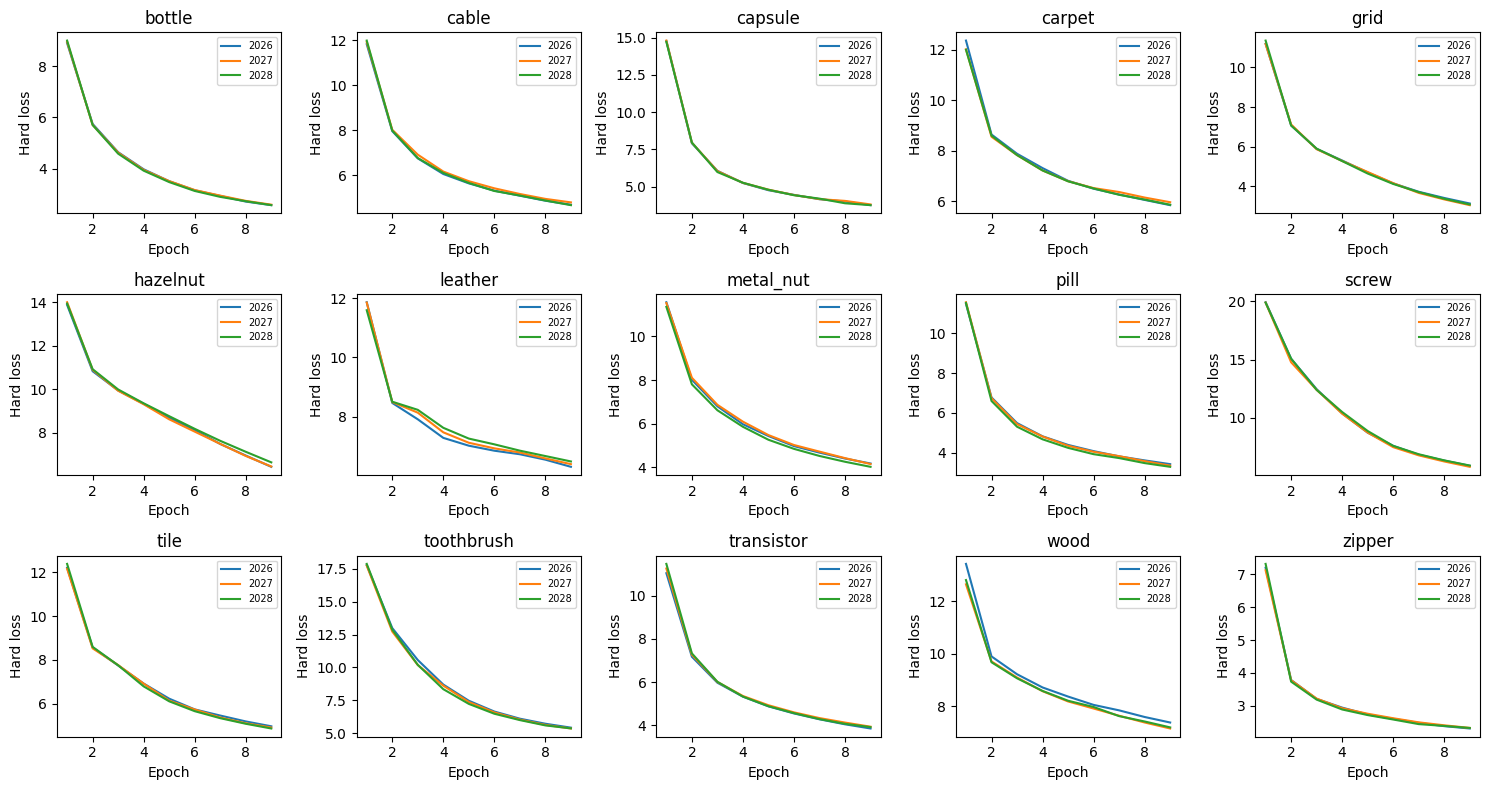

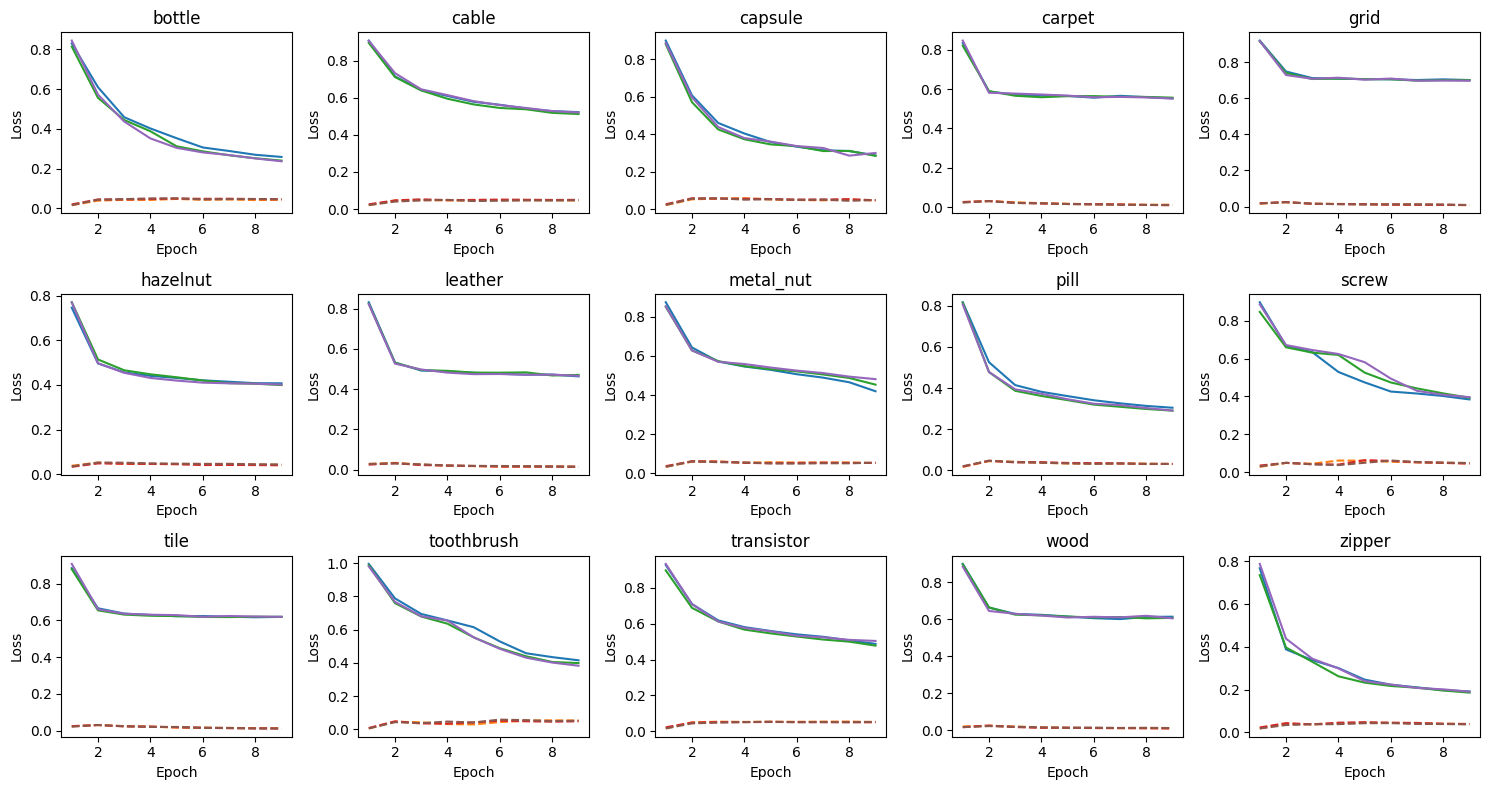

  category  seed  training_seconds  calibration_seconds  evaluation_seconds
    bottle  2026        146.194112             1.635745           37.069070
     cable  2026        159.082303             2.518194           79.633130
   capsule  2026        155.776444             2.375183           67.874890
    carpet  2026        199.391078             3.106893           70.472203
      grid  2026        216.286350             2.026375           44.249748
  hazelnut  2026        315.875749             7.219140          136.755636
   leather  2026        214.215641             2.499428           69.909018
 metal_nut  2026        157.399605             1.654393           34.398261
      pill  2026        194.535358             2.346942           58.095632
     screw  2026        234.485243             2.508364           78.560582
      tile  2026        167.096915             2.121922           48.364457
toothbrush  2026         42.419869             0.637953           29.005412
transistor  

In [3]:
categories=frozen['categories']
fig,axes=plt.subplots(3,5,figsize=(15,8))
for ax,category in zip(axes.ravel(),categories):
    for row in runs[runs.category.eq(category)].itertuples():
        h=pd.read_csv(R/f'final/runs/{row.experiment_id}-history.csv')
        ax.plot(h.epoch,h.hard,label=str(row.seed))
    ax.set_title(category);ax.set_xlabel('Epoch');ax.set_ylabel('Hard loss');ax.legend(fontsize=7)
fig.tight_layout();plt.show()
fig,axes=plt.subplots(3,5,figsize=(15,8))
for ax,category in zip(axes.ravel(),categories):
    for row in runs[runs.category.eq(category)].itertuples():
        h=pd.read_csv(R/f'final/runs/{row.experiment_id}-history.csv')
        ax.plot(h.epoch,h.autoencoder,label=f'AE/{row.seed}')
        ax.plot(h.epoch,h.student_autoencoder,linestyle='--',label=f'STAE/{row.seed}')
    ax.set_title(category);ax.set_xlabel('Epoch');ax.set_ylabel('Loss')
fig.tight_layout();plt.show()
print(runs[['category','seed','training_seconds','calibration_seconds','evaluation_seconds']].to_string(index=False))

The full CSV histories and epoch snapshots preserve every final fit. They cannot be treated as extra development trials or used to choose a different epoch. Category and seed differences in these curves describe the frozen policy. All numerical failures or interrupted attempts, if any, remain in the append-only registry rather than being removed from the record.

### Native-resolution evaluation and uncertainty

Image AUROC/AP and operating metrics use the shared metric implementation. Pixel AUROC/AP and AU-PRO use the exact native-resolution signed-score sweep, 8-connected regions and FPR<=.30 integration. Native maps are bilinear with align_corners=False. No probability conversion is applied. Whole-image bootstrap uses the same 2,000 resamples as previous models; pixel intervals alone use 4,096 calibration-centered/scaled monotone arctangent bins. Primary pixel point estimates remain exact.

In [4]:
print(inspect.getsource(final.native_evaluation))
macro=pd.DataFrame(summary['macro']).T
print(macro.to_string())
print('Pixel bootstrap quantization bias:',summary['pixel_bootstrap_quantization_bias'])
print('Macro by seed:');print(pd.read_csv(R/'macro_by_seed.csv').to_string(index=False))

def native_evaluation(rows,maps,scores,calibration,category,local):
    inventory=pd.read_csv(ROOT/'outputs/eda/inventory.csv',usecols=['path','height','width']).set_index('path')
    sizes=[(int(inventory.loc[p,'height']),int(inventory.loc[p,'width'])) for p in rows.path]
    count=sum(h*w for h,w in sizes)
    scratch=[local/f'native-{name}.dat' for name in ('scores','truth','regions')]
    vectors=[np.memmap(p,mode='w+',dtype=dtype,shape=(count,)) for p,dtype in zip(scratch,(np.float32,np.uint8,np.float64))]
    positive=np.zeros((len(rows),4096),np.uint32);negative=np.zeros_like(positive);region=np.zeros_like(positive,dtype=np.float64)
    region_counts=[];cursor=0;pixel_cm=np.zeros((2,2),np.int64);per_image=[]
    for i,(row,size) in enumerate(zip(rows.itertuples(),sizes)):
        native=F.interpolate(torch.from_numpy(np.array(maps[i:i+1,None])),size=size,mode='bilinear',align_corners=False).numpy()[0,0]
        if isinstance(row.mask,str):
            mask_path=ROOT/'data/mvtec_

The reported bootstrap intervals condition on fitted models and thresholds and do not include all fitting/calibration uncertainty. Pixel histogram bias is disclosed separately from primary exact metrics. Averaging seed replicates does not make repeated evaluations of the same test images independent. The point estimates below are arithmetic category means, equally weighted across all 15 categories and three seeds.

### All-category metrics, confusion matrices and defect types

All 45 runs and all nine metrics are displayed, followed by category means and seed-evaluation confusion counts. Defect-type tables compare each real defect class with that category’s test normals using the same frozen threshold. No category is excluded because it performs poorly.

In [5]:
print(runs[['category','seed']+metrics].to_string(index=False))
category=pd.read_csv(R/'all_category_means.csv').set_index('category')
print(category.to_string())
print('Confusion counts across three seed-evaluations:');print(runs.groupby('category')[['tn','fp','fn','tp']].sum().to_string())
defects=pd.read_csv(R/'per_defect_results.csv')
print(defects.groupby(['category','defect'])[['auroc','ap','recall','fpr','precision','f1']].mean().to_string())
print('Textures versus objects:');print(pd.read_csv(R/'texture_object.csv').to_string(index=False))

  category  seed  image_auroc  image_ap  pixel_auroc  pixel_ap   au_pro   recall      fpr  precision       f1
    bottle  2026     0.968254  0.984701     0.926346  0.670788 0.829471 0.936508 0.000000   1.000000 0.967213
     cable  2026     0.592016  0.774225     0.897855  0.486648 0.759351 0.304348 0.017241   0.965517 0.462810
   capsule  2026     0.769047  0.918563     0.904848  0.323105 0.882913 0.477064 0.130435   0.945455 0.634146
    carpet  2026     0.950642  0.985910     0.963542  0.656961 0.892581 0.943820 0.535714   0.848485 0.893617
      grid  2026     0.916458  0.972235     0.933164  0.368888 0.841831 0.491228 0.000000   1.000000 0.658824
  hazelnut  2026     0.928214  0.969763     0.925740  0.521631 0.901557 0.828571 0.000000   1.000000 0.906250
   leather  2026     0.998981  0.999646     0.995523  0.586070 0.986979 1.000000 0.750000   0.793103 0.884615
 metal_nut  2026     0.548387  0.871586     0.932732  0.698860 0.645589 0.580645 0.636364   0.794118 0.670807
      pill

These confusion counts sum repeated seed evaluations of the same images; they are not three times as many independent test cases. Texture/object averages and the full defect-type table expose behavior hidden by the macro mean. Genuine category-specific failures and small-defect cases are analyzed below, while the configuration remains unchanged.

### Reserved-normal calibration and score floors

Each fresh model fits its own higher 95th-percentile threshold on the existing clean calibration partition, with strict greater comparison. Exact float32 score values are promoted before CSV export and parsed with round-trip precision. Report ties, sample sizes, empirical normal FPR and threshold sensitivity without using test labels to alter calibration.

  category  seed  image_threshold  calibration_images  calibration_unique_scores  calibration_fpr  development_exceedance      fpr
    bottle  2026         0.506691                  31                          1         0.000000                0.032258 0.000000
     cable  2026         0.535737                  33                         33         0.030303                0.000000 0.017241
   capsule  2026         0.366305                  32                         32         0.031250                0.062500 0.130435
    carpet  2026         0.329155                  42                         42         0.047619                0.047619 0.535714
      grid  2026         0.769681                  39                         39         0.025641                0.000000 0.000000
  hazelnut  2026         0.342420                  58                         58         0.034483                0.034483 0.000000
   leather  2026         0.303777                  36                         36   

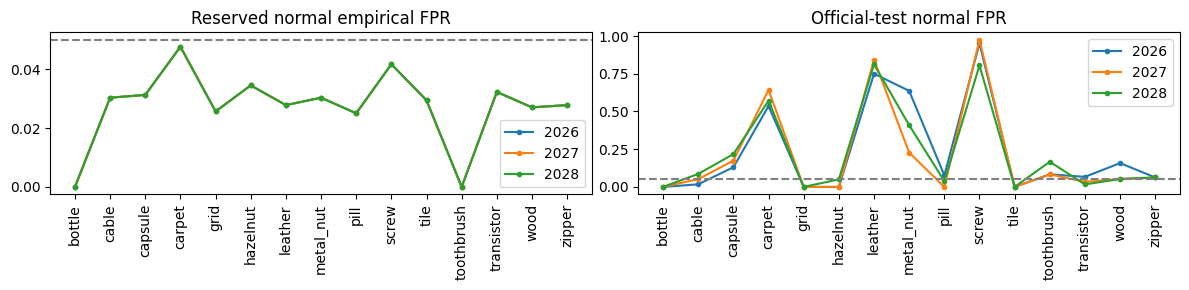

bottle 2026 {'threshold': 0.5066908597946167, 'calibration_distribution': {'n': 31, 'min': 0.5066908597946167, 'median': 0.5066908597946167, 'mean': 0.5066908597946167, 'std': 0.0, 'q90': 0.5066908597946167, 'q95': 0.5066908597946167, 'max': 0.5066908597946167}, 'unique_calibration_scores': 1, 'largest_tie_count': 31, 'observed_calibration_fpr': 0.0, 'bootstrap_threshold_p025_p50_p975': [0.5066908597946167, 0.5066908597946167, 0.5066908597946167], 'leave_one_out_threshold_range': [0.5066908597946167, 0.5066908597946167], 'future_fpr_order_statistic_95': None}
carpet 2026 {'threshold': 0.3291548490524292, 'calibration_distribution': {'n': 42, 'min': 0.06781019270420074, 'median': 0.1347954198718071, 'mean': 0.158382041291112, 'std': 0.09100048752739316, 'q90': 0.24321821779012676, 'q95': 0.3252888590097424, 'max': 0.5222468376159668}, 'unique_calibration_scores': 42, 'largest_tie_count': 1, 'observed_calibration_fpr': 0.047619047619047616, 'bootstrap_threshold_p025_p50_p975': [0.2108388

In [6]:
calibration=pd.read_csv(R/'calibration_summary.csv',float_precision='round_trip')
print(calibration.to_string(index=False))
print({'normal_calibration_mean_fpr':summary['calibration_fpr_mean'],'test_macro_fpr':summary['test_fpr_macro'],'runs_with_ties':summary['calibration_runs_with_ties']})
fig,axes=plt.subplots(1,2,figsize=(12,3))
for seed,g in calibration.groupby('seed'):
    axes[0].plot(g.category,g.calibration_fpr,marker='.',label=str(seed))
    axes[1].plot(g.category,g.fpr,marker='.',label=str(seed))
for ax,title in zip(axes,['Reserved normal empirical FPR','Official-test normal FPR']):
    ax.axhline(.05,color='gray',linestyle='--');ax.set_title(title);ax.tick_params(axis='x',rotation=90);ax.legend()
fig.tight_layout();plt.show()
for item in manifest['models']:
    r=json.loads((ROOT/item['result']).read_text())
    if item['category'] in ('bottle','carpet','leather','toothbrush'):
        c=r['calibration'];print(item['category'],item['seed'],{k:c[k] for k in ['threshold','calibration_distribution','unique_calibration_scores','largest_tie_count','observed_calibration_fpr','bootstrap_threshold_p025_p50_p975','leave_one_out_threshold_range','future_fpr_order_statistic_95']})

A nominal 5% calibration rule does not guarantee 5% future FPR. Small samples, score ties and distribution differences are visible in the per-run records. Continuous-score Beta intervals are marked inapplicable when ties occur. Bottle’s border-driven normal score floor is retained rather than removed after seeing test results; a zero-width bootstrap on tied scores does not establish certainty.

### Genuine failure analysis across all 15 categories

The tables identify actual false alarms, misses, tiny masks, and image misses with a local pixel alarm overlapping the defect. Pixel overlap alone is not a guarantee of good localization. Genuine panels show original images, teacher/student and student/AE discrepancy maps, the unselected combination, selected-map pixel alarms and ground truth. Dataset-derived images remain in ignored local artifacts, following the project publication policy.

In [7]:
print(pd.read_csv(R/'category_failure_summary.csv').to_string(index=False))
print(pd.read_csv(R/'small_defect_summary.csv').to_string(index=False))
examples=pd.read_csv(R/'failure_examples.csv',float_precision='round_trip')
print(examples.to_string(index=False))
print('Image FN evaluations with localized pixel overlap:',summary['fn_with_pixel_overlap'])

  category  seed_evaluations  false_positives  false_negatives  fn_with_any_localized_pixel_alarm  tiny_defects  tiny_defect_recall  normal_peak_border_fraction
    bottle               249                0               11                                 11             0                 NaN                     1.000000
     cable               450                9              168                                142             0                 NaN                     0.971264
   capsule               396               12              154                                147            21            0.666667                     0.753623
    carpet               351               49               14                                 14             0                 NaN                     0.392857
      grid               234                0               54                                 51             0                 NaN                     0.603175
  hazelnut               330      

The example inventory covers every category and records source paths, seeds, outcomes, threshold values and mask areas. No nonexistent false positive/negative is fabricated. Examine carpet/leather normal alarms, screw image detection, scratches and small defect masks in the retained panels. Background pixel alarm area documents localization spread; receptive-field or padding explanations remain hypotheses unless directly supported. Original MVTec AD is not a comprehensive logical-anomaly benchmark.

### Local anomaly-map panels — real executed output retained locally

The following replay displays the already generated genuine panels for all categories; it performs no model forward or feature extraction. The full executed notebook with these licensed dataset-derived outputs is saved under outputs/efficientad/final/. The Git notebook preserves the executed code and inventory, with image outputs removed. All aggregate charts and numeric outputs remain committed.

In [8]:
from IPython.display import display,Image as DisplayImage
for row in examples.itertuples():
    display(DisplayImage(filename=str(ROOT/row.panel)))
    if isinstance(row.zoom_panel,str):
        display(DisplayImage(filename=str(ROOT/row.zoom_panel)))

The local full notebook contains the actual panels. Committed output removal is a publication/data-license choice, not a claim that the visualization cell was skipped. Global and combined maps are shown only for failure analysis and never replace the selected local score in the benchmark.

### Exact six-model comparison and paired uncertainty

Compare all nine metrics from the exact recorded Basic CNN, convolutional autoencoder, PatchCore variant, SuperSimpleNet Lite, PaDiM and EfficientAD reduced-budget results. Category/seed matched image-bootstrap differences use shared draws. Paired category-resampling intervals cover all nine primary metrics with seed means inside categories; this measures a different uncertainty target from fixed-category image resampling.

             Basic CNN  Convolutional Autoencoder  PatchCore variant  SuperSimpleNet Lite     PaDiM  EfficientAD-S reduced-budget
image_auroc   0.712589                   0.634623           0.967572             0.964783  0.897933                      0.816298
image_ap      0.858954                   0.827916           0.988538             0.986239  0.946389                      0.918593
pixel_auroc   0.785832                   0.690002           0.972944             0.952850  0.965920                      0.919887
pixel_ap      0.235382                   0.110897           0.540154             0.436077  0.453764                      0.498476
au_pro        0.549807                   0.449350           0.920399             0.856502  0.911929                      0.818373
recall        0.401760                   0.235000           0.890435             0.892012  0.696493                      0.665639
fpr           0.098341                   0.093944           0.171806             0.166249 

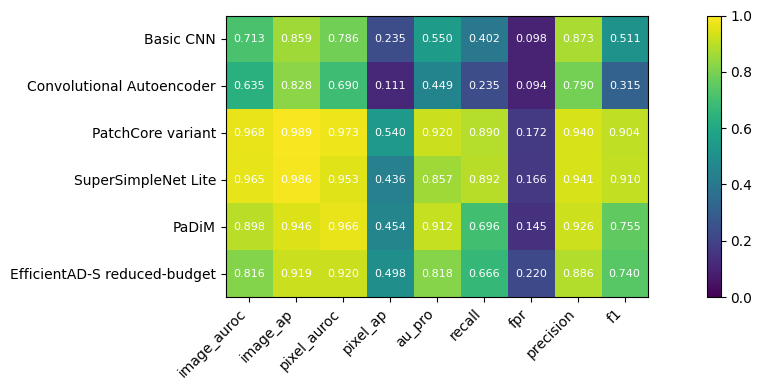

In [9]:
comparison=pd.read_csv(R/'model_macro_comparison.csv',index_col=0)
print(comparison.to_string())
print(pd.read_csv(R/'paired_image_difference_intervals.csv').to_string(index=False))
print(pd.read_csv(R/'paired_category_difference_intervals.csv').to_string(index=False))
print(pd.read_csv(R/'paired_prediction_disagreements.csv').groupby('comparison').sum(numeric_only=True).drop(columns='seed').to_string())
fig,ax=plt.subplots(figsize=(12,4))
a=comparison.T[metrics]
im=ax.imshow(a.to_numpy(),vmin=0,vmax=1,cmap='viridis')
ax.set_xticks(range(len(metrics)),metrics,rotation=45,ha='right');ax.set_yticks(range(len(a)),a.index)
for i in range(len(a)):
    for j in range(len(metrics)):ax.text(j,i,f'{a.iloc[i,j]:.3f}',ha='center',va='center',fontsize=8,color='white')
fig.colorbar(im,ax=ax);fig.tight_layout();plt.show()

Lower FPR is favorable while higher values are generally favorable for the other metrics, so a single color scale is descriptive rather than an overall ranking. Previous results are untouched. No small difference in macro means is declared statistically superior; intervals are conditional/exploratory and no multiple-comparison correction is applied. Pixel bootstrap approximation and different fitting/latency scopes limit comparisons further.

### Actual runtime, memory, storage and deployment costs

Measured per-run training, calibration, test inference, native metrics/bootstrap, latency sweeps and total pipeline times replace projections. Model p50/p95 values are averages of 45 per-run percentiles, not pooled latency quantiles. End-to-end includes decoded-image preprocessing, transfer, full two-map eager execution and CPU map postprocessing; separate decode-inclusive timing is retained.

In [10]:
print(pd.read_csv(R/'model_cost_comparison.csv').to_string(index=False))
print(json.dumps({k:v for k,v in summary.items() if k not in ('macro','pixel_bootstrap_quantization_bias')},indent=2))
print(runs[['category','seed','training_seconds','calibration_seconds','inference_seconds','native_metrics_bootstrap_seconds','latency_seconds','wall_seconds','model_p50_ms','model_p95_ms','end_to_end_p50_ms','end_to_end_p95_ms','cpu_peak_rss_gib','train_peak_vram_gib','checkpoint_bytes']].to_string(index=False))

                       model  training_fitting_seconds  evaluation_seconds  model_p50_ms  model_p95_ms  end_to_end_p50_ms  end_to_end_p95_ms  peak_training_vram_gib  peak_inference_vram_gib  peak_cpu_rss_gib  max_checkpoint_bytes  shared_backbone_bytes  single_category_deployment_bytes  recorded_feature_cache_bytes                                                                                                                                                                                                     caveat
                   Basic CNN                486.625305         2123.112045      3.139279      4.629034          12.538484          15.205255                0.480465                 0.044080               NaN                343117                      0                            343117                             0 Recorded category checkpoints; pretrained shared-backbone storage/pretraining and cache extraction may be additional. Basic CNN/AE evaluation CPU RSS not recorded.

Actual training totals 2.382 hours and run pipelines 3.346 hours. The historical projections were 2.68 training hours and 10.16 conservative total hours. Peak sampled worker RSS is 5.804 GiB. GPU allocator peaks exclude driver/context memory; manager RSS is separate. Recorded fitting effort excludes upstream teacher/backbone pretraining, and older Basic CNN/AE evaluation RAM was not recorded. Full two-map timing is conservative for a future optimized local-only deployment; no optimization was silently adopted here.

### Conclusions and complete retained research record

The full measured findings, category failure evidence, paired comparisons and limitations follow. This reduced variant preserves PDN teacher identity, short-budget training, missing penalty, global-branch rejection and calibration issues. It does not reproduce the paper’s 70k-step/penalty-trained model. All source/partition/teacher/checkpoint/map/score identities and prior milestone preservation are validated separately before publication. Notebook 07 — Final Model Comparison remains unstarted.

In [11]:
print((ROOT/'docs/efficientad_final_results.md').read_text(encoding='utf-8'))

# EfficientAD-S reduced-budget final benchmark

All 45 frozen category-seed models completed. The initial pilot and four development fits remain separate. No architecture, hyperparameter, score or threshold policy changed using test results.

Frozen identity: `d728cf544ebc6f0c3d012adbca044a7aa5ddf4c0ced2e3210bef19b77a71d321`. Nine full epochs, batch one, deterministic FP32, pinned PDN teacher, dual-head student and AE objectives, no external-image penalty. The selected score is normalized local-map maximum; global/combined maps are retained for analysis only. This is not a paper-equivalent reproduction.

## All nine macro metrics

| Metric | Mean | Seed SD | Conditional image-bootstrap 95% interval |
|---|---:|---:|---|
| image_auroc | 0.816298 | 0.011074 | [0.797444, 0.833745] |
| image_ap | 0.918593 | 0.005765 | [0.906335, 0.931228] |
| pixel_auroc | 0.919887 | 0.001631 | [0.911106, 0.928618] |
| pixel_ap | 0.498476 | 0.007130 | [0.478785, 0.517498] |
| au_pro | 0.818373 | 0.005692 |

This is the final frozen evaluation story, with the initial pilot, selected and rejected development trials, all final results and failures retained. The separate final validation report records coverage, deep artifact checks, notebook integrity and test outcomes. Remaining scientific limitations are not erased by completing the engineering benchmark.

### Post-evaluation visual review: actual observations

The all-category contact sheet and individual screw/leather panels were visually inspected after all 45 evaluations. The following observations refer to the first retained genuine case in each category; full-resolution panels and additional fine-defect zooms remain local. No model, score, border handling or threshold was changed. Heatmaps have separate signed-value colorbars, so brightness alone is not a cross-branch comparison.

| Category / seed | Genuine source | Outcome | Score / cutoff | Visual observation |
|---|---|---|---|---|
| bottle / 2027 | `bottle/test/contamination/000.png` | FN | 0.47813 / 0.47813 | Central contamination responds locally, with bright corner/rim responses; the image is missed at a score tied with its cutoff. |
| cable / 2026 | `cable/test/missing_cable/006.png` | FN | 0.520378 / 0.535737 | The missing-cable interior produces a clear response and overlapping pixel alarms, yet its image maximum is below the cutoff. |
| capsule / 2026 | `capsule/test/faulty_imprint/005.png` | FN | 0.305825 / 0.366305 | A compact response aligns with the faulty imprint on the red half; it remains below the image cutoff. |
| carpet / 2026 | `carpet/test/color/002.png` | FN | 0.315676 / 0.329155 | The color defect receives a local response alongside off-target texture spots. The unselected AE map has strong border responses. |
| grid / 2026 | `grid/test/thread/009.png` | FN | 0.660734 / 0.769681 | A diagonal thread is visible in the local response; the alarm band is broader/more connected than the fragmented ground-truth mask. |
| hazelnut / 2027 | `hazelnut/test/cut/001.png` | FN | 0.389068 / 0.389507 | Two cut regions respond, but the image maximum is only slightly below the calibrated cutoff. |
| leather / 2026 | `leather/test/good/030.png` | FP | 0.797814 / 0.303777 | A genuine normal texture has a bright local hot spot and diffuse pixel alarms despite an empty mask: an actual false positive. |
| metal_nut / 2027 | `metal_nut/test/flip/007.png` | FN | 0.303931 / 0.310598 | The flipped object has broad ring/boundary responses and partial object alarms, but still fails the image cutoff. |
| pill / 2028 | `pill/test/faulty_imprint/011.png` | FN | 0.410777 / 0.510062 | The faulty-imprint area responds together with rim/off-target spots; the image remains below its cutoff. |
| screw / 2028 | `screw/test/scratch_neck/020.png` | FN | 0.362458 / 0.399855 | Neck scratches receive local pixel alarms while the image is missed; the unselected AE map also emphasizes the head/tip. |
| tile / 2026 | `tile/test/glue_strip/003.png` | FN | 1.12063 / 1.27803 | The large glue-strip region responds broadly and overlaps the mask, but its maximum is below the image cutoff. |
| toothbrush / 2026 | `toothbrush/test/defective/014.png` | FN | 0.245262 / 0.261065 | The bristle-top region responds, with partial coverage and separate off-target spots; the image is still missed. |
| transistor / 2028 | `transistor/test/damaged_case/008.png` | FN | 0.276791 / 0.322679 | Upper-case damage receives a local response with broader surrounding responses; the image maximum remains below its cutoff. |
| wood / 2026 | `wood/test/liquid/002.png` | FN | 0.360663 / 0.373221 | Three liquid regions are visible in the local map and alarm overlay, yet the image maximum falls below its cutoff. |
| zipper / 2028 | `zipper/test/squeezed_teeth/001.png` | FN | 0.449607 / 0.463272 | Squeezed upper teeth receive a local response alongside border responses; the image remains below its cutoff. |

Observed versus proposed explanation: localized responses below an image cutoff, normal-texture alarms, corner/border responses and spatial spread beyond masks are directly visible. Padding/receptive fields, insufficient optimization, missing external regularization or acquisition-domain differences are possible explanations; these panels do not causally separate them. A combined/global map looking different does not establish that an alternative score would improve the frozen benchmark. No alternative test-driven score was selected.

The frozen reduced variant met the compute target but is not a reliable universal operating-point detector here. The severe screw failure and carpet/leather false alarms remain central limitations even where pixel ranking or image AP is high. There is no claim of full-paper equivalence or deployment readiness.

### Paired uncertainty: selected exact-image contrasts

Differences below are EfficientAD minus the recorded baseline, using the same 2,000 whole-image draws and fixed models/thresholds. Lower FPR is favorable. These conditional intervals differ from the separately retained 15-category resampling intervals and do not imply unrestricted statistical superiority.

| Baseline | Metric | Difference | Conditional paired 95% interval |
|---|---|---:|---|
| Basic CNN | image_auroc | +0.1037 | [+0.0778, +0.1277] |
| Basic CNN | fpr | +0.1217 | [+0.0942, +0.1522] |
| Basic CNN | f1 | +0.2295 | [+0.2065, +0.2522] |
| Convolutional Autoencoder | image_auroc | +0.1817 | [+0.1482, +0.2148] |
| Convolutional Autoencoder | fpr | +0.1261 | [+0.0965, +0.1567] |
| Convolutional Autoencoder | f1 | +0.4254 | [+0.3972, +0.4540] |
| PatchCore variant | image_auroc | -0.1513 | [-0.1705, -0.1341] |
| PatchCore variant | fpr | +0.0483 | [+0.0135, +0.0852] |
| PatchCore variant | f1 | -0.1643 | [-0.1853, -0.1457] |
| SuperSimpleNet Lite | image_auroc | -0.1485 | [-0.1673, -0.1300] |
| SuperSimpleNet Lite | fpr | +0.0538 | [+0.0207, +0.0867] |
| SuperSimpleNet Lite | f1 | -0.1698 | [-0.1903, -0.1528] |
| PaDiM | image_auroc | -0.0816 | [-0.1046, -0.0598] |
| PaDiM | fpr | +0.0756 | [+0.0374, +0.1145] |
| PaDiM | f1 | -0.0153 | [-0.0376, +0.0067] |
